[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/16_data-quality.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 16 of 21*

# Data Quality & Observability

Trustworthy data: the dimensions of quality, tests for nulls, uniqueness, ranges and freshness, anomaly detection, reconciliation, data contracts, lineage and running incidents. This is where a QA background becomes a superpower.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Wrong numbers that look right are worse than a broken dashboard. Your testing instincts are a superpower here.

**What interviewers really test here:** What you test and where, anomaly detection, contracts and how you handle an incident.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Bad data is worse than no data *(Basics)*
- [ ] 2. Catching problems nobody wrote a rule for *(Core)*
- [ ] 3. Handling failures: quarantine, contracts and debugging *(Core)*
- [ ] 4. Observability and incidents *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Where to put checks

| Stage | Check |
| --- | --- |
| On arrival | schema, file complete, row count above zero |
| After transform | keys unique, not null, ranges, joins kept their rows |
| Before publish | totals reconcile, no sudden changes |
| After publish | freshness, drift, monitored continuously |

---
# Part 2: Lessons, step by step

## Lesson 1: Bad data is worse than no data

*Level: Basics*

A broken dashboard gets noticed. A dashboard quietly showing wrong numbers gets used to make decisions. **Trust is the real product of a data team.**



| Dimension | Question | Example test |
| --- | --- | --- |
| Completeness | is anything missing? | null rate of 0.5 in a column |
| Uniqueness | any duplicates? | keys 1, 2, 2, 3 fail on 2 |
| Validity | are values allowed? | "PAID" isn't in paid, refunded |
| Range | are values possible? | age 200 |
| Consistency | do tables agree? | half the foreign keys have no match |
| Timeliness | is it fresh? | 50 minutes past the SLA |



**Your QA background is a real advantage here.** Most data engineers learned testing late. Boundary values, equivalence classes and "how could this break?" are exactly the right instincts.



**Start by profiling:** for [1, None, 3, 3], the count is 4, nulls 1, distinct 2, min 1, max 3. Profile any new source before writing rules, because you'll be surprised.



**Tests as configuration,** as in dbt or Great Expectations:



```python
models:
  - name: orders
    columns:
      - name: order_id
        tests: [not_null, unique]
      - name: status
        tests:
          - accepted_values: {values: [paid, refunded]}
```

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q4](#q4), [Q5](#q5), [Q6](#q6), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 2: Catching problems nobody wrote a rule for

*Level: Core*

Rules catch known problems. **Anomaly detection** catches surprises: a source sends half its usual rows, with every value still valid.



**Volume check.** Past counts 100, 102, 98, 101, 99 have mean 100 and standard deviation 1.58. Today's 50 has z = (50 − 100) / 1.58 = **−31.6**, so raise an alert. 103 has z = 1.9, which is fine.



**Seasonality.** If weekends are always low, comparing to the last few days alerts every Saturday. Compare with the **same weekday** instead. The chart shows why.



**Distribution drift.** Row counts can be perfect while the mix changes. Bins 0.8/0.2 shifting to 0.2/0.8 give a PSI of 1.66, a large shift. A common rule: below 0.1 is stable, above 0.25 is drift. These cut-offs are conventions.



**Alert fatigue.** If an alert is right only half the time, people stop reading it. Track each alert's precision, and fix or delete the noisy ones. An alert nobody acts on is worse than none.



| Severity | Example | Action |
| --- | --- | --- |
| Warn | 2% nulls, limit 1% | notify, continue |
| Error | 50% nulls, limit 10% | stop publishing |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

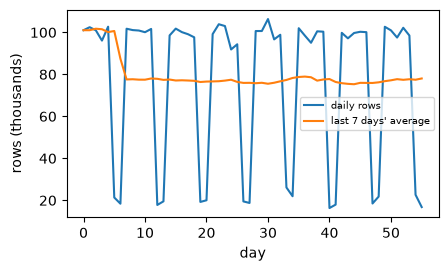

In [2]:
def seasonality_chart():
    rng = np.random.default_rng(1)
    days = np.arange(56)
    counts = np.where(days % 7 >= 5, 20, 100) + rng.normal(0, 3, 56)
    recent = np.array([counts[max(0, d - 7):d].mean() if d else counts[0] for d in days])
    fig, ax = plt.subplots(figsize=(4.8, 2.7))
    ax.plot(days, counts, label="daily rows")
    ax.plot(days, recent, label="last 7 days' average")
    ax.set_xlabel("day")
    ax.set_ylabel("rows (thousands)")
    ax.legend(fontsize=7)


seasonality_chart()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q12](#q12), [Q13](#q13), [Q15](#q15), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 3: Handling failures: quarantine, contracts and debugging

*Level: Core*

**Quarantine rows, don't lose them.** Split good rows from bad ones, recording why: id None and amount −1 gets reasons null\_id and negative. Good rows flow on, and bad ones wait to be looked at.



**Data contracts.** Most breakages begin upstream, when a team changes a column without knowing who depends on it. A contract is an agreement, checked in code, on schema, meaning and freshness:



```python
{"id": ("int", not null), "name": ("str", nullable), "age": ("int", not null)}
row {"id": "7", "name": None, "age": None}  →  null:age, type:id
```



Run contract checks in the **producer's CI**, so a breaking change fails before it ships.



**Debug by layer.** Count rows at every step: raw 1000, clean 990, joined 400, final 395. The join lost 59.6%, so look there, likely at a key mismatch.



**Test logic changes safely.** Before releasing a change, build both versions and compare them. Keys only in old: 1. Only in new: 4. Changed: 3. Then explain each difference, because every difference is either intended or a bug.



**Reconcile with the source.** A total of 1000 vs 1001 is within a 1% tolerance, and 1000 vs 900 isn't.

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17), [Q19](#q19), [Q20](#q20), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 4: Observability and incidents

*Level: Advanced*

**Five things to watch on every important table:** freshness, volume, schema, distribution and lineage.



**Lineage turns panic into a plan.** If table a breaks, following its consumers shows finance and growth are affected, so you can tell them before they find out.



**When an incident happens:**



1. **Detect:** ideally by your alert, not a stakeholder.
2. **Communicate:** say what's affected and when you'll update again.
3. **Stop the damage:** pause publishing, or roll back.
4. **Fix and backfill.**
5. **Review without blame:** ask what would have caught this sooner, and add that test.



**Measure yourself.** Two incidents, detected after 30 and 10 minutes, resolved after 90 and 50: mean time to detect is 20 minutes, and to resolve 70. If detection is slow, invest in monitoring.



**Tools you'll hear about:** dbt tests, Great Expectations, Soda, Monte Carlo, OpenLineage. Learn the ideas above, and the tools are easy to pick up.

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q9](#q9). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
import statistics


<a id="q1"></a>
### Q1. Null Rate per Column

🟢 Warm-up · *Completeness*

Return the share of None per column, rounded to 4 decimals, sorted by column.

**Examples**

- `rows = [{'a': 1, 'b': None}, {'a': None, 'b': None}]` → `{'a': 0.5, 'b': 1.0}`

In [ ]:
def null_rates(rows):
    """
    Return the share of None per column, rounded to 4 decimals, sorted by
    column.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(null_rates, [
    (([{'a': 1, 'b': None}, {'a': None, 'b': None}],), {'a': 0.5, 'b': 1.0}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension per column.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Nested loops.

```python
def null_rates(rows):
    counts = {}
    for r in rows:
        for k, v in r.items():
            counts[k] = counts.get(k, 0) + (1 if v is None else 0)
    return {k: round(counts[k] / len(rows), 4) for k in sorted(counts)}
```

**Cost:** O(n·c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension per column.

```python
def null_rates(rows):
    return {c: round(sum(r[c] is None for r in rows) / len(rows), 4) for c in sorted(rows[0])}
```

**Cost:** O(n·c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(n·c) time and O(c) space."

"I can do better: A comprehension per column. That's O(n·c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/null-rate-per-column)

<a id="q2"></a>
### Q2. Uniqueness Check

🟢 Warm-up · *Primary keys*

Return (is unique, duplicate key values sorted).

**Examples**

- `keys = [1, 2, 2, 3, 3, 3]` → `(False, [2, 3])`
- `keys = [1, 2]` → `(True, [])`

In [ ]:
def uniqueness(keys):
    """
    Return (is unique, duplicate key values sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(uniqueness, [
    (([1, 2, 2, 3, 3, 3],), (False, [2, 3])),
    (([1, 2],), (True, [])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count with a dictionary.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Count with a dictionary.

```python
def uniqueness(keys):
    counts = {}
    for k in keys:
        counts[k] = counts.get(k, 0) + 1
    dupes = sorted(k for k, c in counts.items() if c > 1)
    return (not dupes, dupes)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter`.

```python
def uniqueness(keys):
    from collections import Counter
    d = sorted(k for k, c in Counter(keys).items() if c > 1)
    return (not d, d)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count with a dictionary. That costs O(n) time and O(n) space."

"I can do better: `Counter`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/uniqueness-check)

<a id="q3"></a>
### Q3. Accepted Values

🟢 Warm-up · *Validity*

Return values not in the allowed set, with their counts, sorted by value. None is ignored.

**Examples**

- `values = ['paid', 'PAID', 'paid', None, 'lost'], allowed = ['paid', 'refunded']` → `{'PAID': 1, 'lost': 1}`

In [ ]:
def bad_values(values, allowed):
    """
    Return values not in the allowed set, with their counts, sorted by value.
    None is ignored.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bad_values, [
    ((['paid', 'PAID', 'paid', None, 'lost'], ['paid', 'refunded']), {'PAID': 1, 'lost': 1}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary and a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary and a loop.

```python
def bad_values(values, allowed):
    out = {}
    for v in values:
        if v is not None and v not in allowed:
            out[v] = out.get(v, 0) + 1
    return dict(sorted(out.items()))
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter`.

```python
def bad_values(values, allowed):
    from collections import Counter
    ok = set(allowed) | {None}
    return dict(sorted(Counter(v for v in values if v not in ok).items()))
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary and a loop. That costs O(n) time and O(d) space."

"I can do better: `Counter`. That's O(n) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/accepted-values)

<a id="q4"></a>
### Q4. Range Check

🟢 Warm-up · *Impossible values*

Return indexes of values outside [lo, hi].

**Examples**

- `values = [5, -1, 200, 50], lo = 0, hi = 120` → `[1, 2]`

In [ ]:
def out_of_range(values, lo, hi):
    """
    Return indexes of values outside [lo, hi].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(out_of_range, [
    (([5, -1, 200, 50], 0, 120), [1, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def out_of_range(values, lo, hi):
    out = []
    for i, v in enumerate(values):
        if v < lo or v > hi:
            out.append(i)
    return out
```

**Cost:** O(n) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def out_of_range(values, lo, hi):
    return [i for i, v in enumerate(values) if not lo <= v <= hi]
```

**Cost:** O(n) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(m) space."

"I can do better: A comprehension. That's O(n) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/range-check)

<a id="q5"></a>
### Q5. Referential Integrity

🟢 Warm-up · *Do the keys exist?*

Return the share of foreign keys without a match, rounded to 4 decimals, plus the unmatched values sorted.

**Examples**

- `fks = [1, 2, 9, 9], pks = [1, 2, 3]` → `(0.5, [9])`

In [ ]:
def ref_integrity(fks, pks):
    """
    Return the share of foreign keys without a match, rounded to 4 decimals,
    plus the unmatched values sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ref_integrity, [
    (([1, 2, 9, 9], [1, 2, 3]), (0.5, [9])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check a list for each key.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Check a list for each key.

```python
def ref_integrity(fks, pks):
    missing = []
    for k in fks:
        if k not in pks:
            missing.append(k)
    return (round(len(missing) / len(fks), 4), sorted(set(missing)))
```

**Cost:** O(n·m) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set.

```python
def ref_integrity(fks, pks):
    known = set(pks)
    bad = [k for k in fks if k not in known]
    return (round(len(bad) / len(fks), 4), sorted(set(bad)))
```

**Cost:** O(n + m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check a list for each key. That costs O(n·m) time and O(1) space."

"I can do better: A set. That's O(n + m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/referential-integrity)

<a id="q6"></a>
### Q6. Freshness per Table

🟢 Warm-up · *SLA dashboards*

Given tables' last load time, an SLA in minutes and now, return stale tables with minutes late, sorted by name.

**Examples**

- `last = {'a': 100, 'b': 40}, sla = 30, now = 120` → `[['b', 50]]`

In [ ]:
def stale_tables(last, sla, now):
    """
    Given tables' last load time, an SLA in minutes and now, return stale tables
    with minutes late, sorted by name.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stale_tables, [
    (({'a': 100, 'b': 40}, 30, 120), [['b', 50]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A sorted comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def stale_tables(last, sla, now):
    out = []
    for t in sorted(last):
        age = now - last[t]
        if age > sla:
            out.append([t, age - sla])
    return out
```

**Cost:** O(t log t) time, O(t) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A sorted comprehension.

```python
def stale_tables(last, sla, now):
    return [[t, now - v - sla] for t, v in sorted(last.items()) if now - v > sla]
```

**Cost:** O(t log t) time, O(t) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(t log t) time and O(t) space."

"I can do better: A sorted comprehension. That's O(t log t) time and O(t) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/freshness-per-table)

<a id="q7"></a>
### Q7. Reconcile Totals

🟢 Warm-up · *Do the sums agree?*

Return whether two totals match within a relative tolerance, and the percent difference rounded to 2 decimals.

**Examples**

- `source = 1000, target = 1001, tol = 0.01` → `(True, 0.1)`
- `source = 1000, target = 900, tol = 0.01` → `(False, 10.0)`

In [ ]:
def reconcile_totals(source, target, tol):
    """
    Return whether two totals match within a relative tolerance, and the percent
    difference rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(reconcile_totals, [
    ((1000, 1001, 0.01), (True, 0.1)),
    ((1000, 900, 0.01), (False, 10.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Step by step.

```python
def reconcile_totals(source, target, tol):
    diff = abs(source - target) / source
    return (diff <= tol, round(diff * 100, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def reconcile_totals(source, target, tol):
    d = abs(source - target) / source
    return (d <= tol, round(d * 100, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step. That costs O(1) time and O(1) space."

"I can do better: Compact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/reconcile-totals)

<a id="q8"></a>
### Q8. Alert Fatigue

🟢 Warm-up · *Measure your alerts*

Given (alert, was\_real) records, return precision per alert name, rounded to 2 decimals, sorted. Noisy alerts get ignored, so fix or remove them.

**Examples**

- `records = [('vol', True), ('vol', False), ('null', False), ('null', False)]` → `{'null': 0.0, 'vol': 0.5}`

In [ ]:
def alert_precision(records):
    """
    Given (alert, was_real) records, return precision per alert name, rounded to
    2 decimals, sorted. Noisy alerts get ignored, so fix or remove them.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(alert_precision, [
    (([('vol', True), ('vol', False), ('null', False), ('null', False)],), {'null': 0.0, 'vol': 0.5}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two dictionaries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A grouped comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Two dictionaries.

```python
def alert_precision(records):
    real, total = {}, {}
    for name, ok in records:
        total[name] = total.get(name, 0) + 1
        real[name] = real.get(name, 0) + (1 if ok else 0)
    return {n: round(real[n] / total[n], 2) for n in sorted(total)}
```

**Cost:** O(n) time, O(a) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A grouped comprehension.

```python
def alert_precision(records):
    from collections import defaultdict
    groups = defaultdict(list)
    for name, ok in records:
        groups[name].append(ok)
    return {n: round(sum(v) / len(v), 2) for n, v in sorted(groups.items())}
```

**Cost:** O(n) time, O(a) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two dictionaries. That costs O(n) time and O(a) space."

"I can do better: A grouped comprehension. That's O(n) time and O(a) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/alert-fatigue)

<a id="q9"></a>
### Q9. Incident Metrics

🟢 Warm-up · *Learn from failures*

Given incidents as (started, detected, resolved) minutes, return mean time to detect and to resolve, rounded to 1 decimal.

**Examples**

- `incidents = [(0, 30, 90), (100, 110, 150)]` → `(20, 70)`

In [ ]:
def incident_metrics(incidents):
    """
    Given incidents as (started, detected, resolved) minutes, return mean time
    to detect and to resolve, rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(incident_metrics, [
    (([(0, 30, 90), (100, 110, 150)],), (20, 70)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Generators.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def incident_metrics(incidents):
    detect = resolve = 0
    for s, d, r in incidents:
        detect += d - s
        resolve += r - s
    n = len(incidents)
    return (round(detect / n, 1), round(resolve / n, 1))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Generators.

```python
def incident_metrics(incidents):
    return (round(statistics.mean(d - s for s, d, _ in incidents), 1), round(statistics.mean(r - s for s, _, r in incidents), 1))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(1) space."

"I can do better: Generators. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/incident-metrics)

<a id="q10"></a>
### Q10. Profile a Column

🟢 Warm-up · *Know your data first*

Return (count, nulls, distinct non-null values, min, max) for a list of numbers with None.

**Examples**

- `values = [1, None, 3, 3]` → `(4, 1, 2, 1, 3)`

In [ ]:
def profile(values):
    """
    Return (count, nulls, distinct non-null values, min, max) for a list of
    numbers with None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(profile, [
    (([1, None, 3, 3],), (4, 1, 2, 1, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop tracking everything.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Filter out None, then use built-ins.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop tracking everything.

```python
def profile(values):
    nulls, seen, low, high = 0, [], None, None
    for v in values:
        if v is None:
            nulls += 1
            continue
        if v not in seen:
            seen.append(v)
        low = v if low is None or v < low else low
        high = v if high is None or v > high else high
    return (len(values), nulls, len(seen), low, high)
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Filter out None, then use built-ins.

```python
def profile(values):
    known = [v for v in values if v is not None]
    return (len(values), len(values) - len(known), len(set(known)), min(known), max(known))
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop tracking everything. That costs O(n) time and O(d) space."

"I can do better: Filter out None, then use built-ins. That's O(n) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/profile-a-column)

<a id="q11"></a>
### Q11. Volume Anomaly

🟡 Interview standard · *Is today's row count normal?*

Flag today's count if it's beyond 3 standard deviations from the recent mean. Return (flagged, z score rounded to 2 decimals). Use sample standard deviation.

**Examples**

- `history = [100, 102, 98, 101, 99], today = 50` → `(True, -31.62)`
- `history = [100, 102, 98, 101, 99], today = 103` → `(False, 1.9)`

In [ ]:
def volume_check(history, today):
    """
    Flag today's count if it's beyond 3 standard deviations from the recent
    mean. Return (flagged, z score rounded to 2 decimals). Use sample standard
    deviation.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(volume_check, [
    (([100, 102, 98, 101, 99], 50), (True, -31.62)),
    (([100, 102, 98, 101, 99], 103), (False, 1.9)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute mean and deviation by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The `statistics` module.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute mean and deviation by hand.

```python
def volume_check(history, today):
    mean = sum(history) / len(history)
    var = sum((x - mean) ** 2 for x in history) / (len(history) - 1)
    z = (today - mean) / math.sqrt(var)
    return (abs(z) > 3, round(z, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The `statistics` module.

```python
def volume_check(history, today):
    z = (today - statistics.mean(history)) / statistics.stdev(history)
    return (abs(z) > 3, round(z, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute mean and deviation by hand. That costs O(n) time and O(1) space."

"I can do better: The `statistics` module. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/volume-anomaly)

<a id="q12"></a>
### Q12. Weekly Seasonality

🟡 Interview standard · *Don't alert every Sunday*

Compare today to the same weekday's past counts instead. Given history (oldest first, daily) and today, return the expected value as the mean of the same weekday in prior weeks, and percent difference, rounded to 1 decimal.

**Examples**

- `history = [100, 100, 100, 100, 100, 20, 20, 100, 100, 100, 100, 100, 20, 20], today = 21` → `(100.0, -79.0)`

In [ ]:
def seasonal(history, today):
    """
    Compare today to the same weekday's past counts instead. Given history
    (oldest first, daily) and today, return the expected value as the mean of
    the same weekday in prior weeks, and percent difference, rounded to 1
    decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(seasonal, [
    (([100, 100, 100, 100, 100, 20, 20, 100, 100, 100, 100, 100, 20, 20], 21), (100.0, -79.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop stepping back 7 days.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Slicing with a step.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop stepping back 7 days.

```python
def seasonal(history, today):
    values, i = [], len(history) - 7
    while i >= 0:
        values.append(history[i])
        i -= 7
    expected = sum(values) / len(values)
    return (expected, round(100 * (today - expected) / expected, 1))
```

**Cost:** O(n/7) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Slicing with a step.

```python
def seasonal(history, today):
    same = history[-7::-7]
    expected = sum(same) / len(same)
    return (expected, round(100 * (today - expected) / expected, 1))
```

**Cost:** O(n/7) time, O(n/7) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop stepping back 7 days. That costs O(n/7) time and O(1) space."

"I can do better: Slicing with a step. That's O(n/7) time and O(n/7) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/weekly-seasonality)

<a id="q13"></a>
### Q13. Distribution Drift

🟡 Interview standard · *PSI*

Compare two distributions over bins: PSI = Σ (a − e)·ln(a/e), adding 0.001 to avoid zero. Return PSI rounded to 4 decimals, and 'stable' under 0.1, 'watch' under 0.25, otherwise 'drift'.

**Examples**

- `expected = [0.5, 0.5], actual = [0.5, 0.5]` → `(0.0, 'stable')`
- `expected = [0.8, 0.2], actual = [0.2, 0.8]` → `(1.6591, 'drift')`

In [ ]:
def psi(expected, actual):
    """
    Compare two distributions over bins: PSI = Σ (a − e)·ln(a/e), adding 0.001
    to avoid zero. Return PSI rounded to 4 decimals, and 'stable' under 0.1,
    'watch' under 0.25, otherwise 'drift'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(psi, [
    (([0.5, 0.5], [0.5, 0.5]), (0.0, 'stable')),
    (([0.8, 0.2], [0.2, 0.8]), (1.6591, 'drift')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A generator.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def psi(expected, actual):
    total = 0.0
    for e, a in zip(expected, actual):
        e, a = e + 0.001, a + 0.001
        total += (a - e) * math.log(a / e)
    verdict = "stable"
    if total >= 0.25:
        verdict = "drift"
    elif total >= 0.1:
        verdict = "watch"
    return (round(total, 4), verdict)
```

**Cost:** O(b) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A generator.

```python
def psi(expected, actual):
    p = sum((a - e) * math.log((a + 0.001) / (e + 0.001)) for e, a in zip(expected, actual))
    return (round(p, 4), "stable" if p < 0.1 else "watch" if p < 0.25 else "drift")
```

**Cost:** O(b) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(b) time and O(1) space."

"I can do better: A generator. That's O(b) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/distribution-drift)

<a id="q14"></a>
### Q14. A Small Test Framework

🟡 Interview standard · *How dbt tests work*

Run named checks on rows: not\_null(col), unique(col). Tests are (name, col). Return failing test descriptions, such as 'not\_null(id)', sorted.

**Examples**

- `rows = [{'id': 1, 'e': None}, {'id': 1, 'e': 'x'}], tests = [('not_null', 'id'), ('not_null', 'e'), ('unique', 'id'), ('unique', 'e')]` → `['not_null(e)', 'unique(id)']`

In [ ]:
def run_checks(rows, tests):
    """
    Run named checks on rows: not_null(col), unique(col). Tests are (name, col).
    Return failing test descriptions, such as 'not_null(id)', sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(run_checks, [
    (([{'id': 1, 'e': None}, {'id': 1, 'e': 'x'}], [('not_null', 'id'), ('not_null', 'e'), ('unique', 'id'), ('unique', 'e')]), ['not_null(e)', 'unique(id)']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary of test functions.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs in a loop.

```python
def run_checks(rows, tests):
    failed = []
    for name, col in tests:
        values = [r[col] for r in rows]
        if name == "not_null" and None in values:
            failed.append(f"{name}({col})")
        if name == "unique" and len(set(values)) != len(values):
            failed.append(f"{name}({col})")
    return sorted(failed)
```

**Cost:** O(t·n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary of test functions.

```python
def run_checks(rows, tests):
    checks = {"not_null": lambda v: None not in v, "unique": lambda v: len(set(v)) == len(v)}
    return sorted(f"{n}({c})" for n, c in tests if not checks[n]([r[c] for r in rows]))
```

**Cost:** O(t·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs in a loop. That costs O(t·n) time and O(n) space."

"I can do better: A dictionary of test functions. That's O(t·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/a-small-test-framework)

<a id="q15"></a>
### Q15. Severity: Warn or Stop?

🟡 Interview standard · *Not all failures are equal*

Each check has (name, failure\_rate, warn\_limit, error\_limit). Return (status: 'pass', 'warn' or 'error' for the worst, names at error sorted).

**Examples**

- `checks = [('nulls', 0.02, 0.01, 0.1), ('dupes', 0.0, 0.0, 0.01)]` → `('warn', [])`
- `checks = [('nulls', 0.5, 0.01, 0.1)]` → `('error', ['nulls'])`

In [ ]:
def severity(checks):
    """
    Each check has (name, failure_rate, warn_limit, error_limit). Return
    (status: 'pass', 'warn' or 'error' for the worst, names at error sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(severity, [
    (([('nulls', 0.02, 0.01, 0.1), ('dupes', 0.0, 0.0, 0.01)],), ('warn', [])),
    (([('nulls', 0.5, 0.01, 0.1)],), ('error', ['nulls'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with flags.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Comprehensions.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop with flags.

```python
def severity(checks):
    errors, warned = [], False
    for name, rate, warn, err in checks:
        if rate > err:
            errors.append(name)
        elif rate > warn:
            warned = True
    status = "error" if errors else "warn" if warned else "pass"
    return (status, sorted(errors))
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Comprehensions.

```python
def severity(checks):
    errors = sorted(n for n, r, _, e in checks if r > e)
    warned = any(r > w for _, r, w, _ in checks)
    return ("error" if errors else "warn" if warned else "pass", errors)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with flags. That costs O(c) time and O(c) space."

"I can do better: Comprehensions. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/severity-warn-or-stop)

<a id="q16"></a>
### Q16. Quarantine Bad Rows

🟡 Interview standard · *Don't block the good ones*

Split rows into good and quarantined, with reasons. Rules: id not None, amount ≥ 0. Return (good ids, [id, reasons]).

**Examples**

- `rows = [{'id': 1, 'amount': 5}, {'id': None, 'amount': -1}, {'id': 3, 'amount': -2}]` → `([1], [[None, ['null_id', 'negative']], [3, ['negative']]])`

In [ ]:
def quarantine(rows):
    """
    Split rows into good and quarantined, with reasons. Rules: id not None,
    amount ≥ 0. Return (good ids, [id, reasons]).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(quarantine, [
    (([{'id': 1, 'amount': 5}, {'id': None, 'amount': -1}, {'id': 3, 'amount': -2}],), ([1], [[None, ['null_id', 'negative']], [3, ['negative']]])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A rule table.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def quarantine(rows):
    good, bad = [], []
    for r in rows:
        reasons = []
        if r["id"] is None:
            reasons.append("null_id")
        if r["amount"] < 0:
            reasons.append("negative")
        if reasons:
            bad.append([r["id"], reasons])
        else:
            good.append(r["id"])
    return (good, bad)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A rule table.

```python
def quarantine(rows):
    rules = {"null_id": lambda r: r["id"] is None, "negative": lambda r: r["amount"] < 0}
    checked = [(r, [n for n, bad in rules.items() if bad(r)]) for r in rows]
    return ([r["id"] for r, why in checked if not why], [[r["id"], why] for r, why in checked if why])
```

**Cost:** O(n·r) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(n) time and O(n) space."

"I can do better: A rule table. That's O(n·r) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/quarantine-bad-rows)

<a id="q17"></a>
### Q17. Check a Data Contract

🟡 Interview standard · *Promises between teams*

A contract lists columns with type and nullable. Given a sample row, return violations, sorted: 'missing:x', 'type:x', 'null:x'.

**Examples**

- `contract = {'id': ('int', False), 'name': ('str', True), 'age': ('int', False)}, row = {'id': '7', 'name': None, 'age': None}` → `['null:age', 'type:id']`

In [ ]:
def contract_violations(contract, row):
    """
    A contract lists columns with type and nullable. Given a sample row, return
    violations, sorted: 'missing:x', 'type:x', 'null:x'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(contract_violations, [
    (({'id': ('int', False), 'name': ('str', True), 'age': ('int', False)}, {'id': '7', 'name': None, 'age': None}), ['null:age', 'type:id']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary of types.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def contract_violations(contract, row):
    out = []
    for col, (kind, nullable) in contract.items():
        if col not in row:
            out.append("missing:" + col)
        elif row[col] is None:
            if not nullable:
                out.append("null:" + col)
        elif (kind == "int" and not isinstance(row[col], int)) or (kind == "str" and not isinstance(row[col], str)):
            out.append("type:" + col)
    return sorted(out)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary of types.

```python
def contract_violations(contract, row):
    types = {"int": int, "str": str}
    out = []
    for col, (kind, nullable) in contract.items():
        if col not in row:
            out.append(f"missing:{col}")
        elif row[col] is None and not nullable:
            out.append(f"null:{col}")
        elif row[col] is not None and not isinstance(row[col], types[kind]):
            out.append(f"type:{col}")
    return sorted(out)
```

**Cost:** O(c log c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(c) time and O(c) space."

"I can do better: A dictionary of types. That's O(c log c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/check-a-data-contract)

<a id="q18"></a>
### Q18. Impact Analysis

🟡 Interview standard · *Who's affected?*

lineage maps a table to its direct consumers. consumers\_of maps a table to teams. Return teams affected if a table is broken, sorted.

**Examples**

- `lineage = {'a': ['b', 'c'], 'b': ['d']}, owners = {'d': ['finance'], 'c': ['growth'], 'a': []}, table = 'a'` → `['finance', 'growth']`

In [ ]:
def impacted(lineage, owners, table):
    """
    lineage maps a table to its direct consumers. consumers_of maps a table to
    teams. Return teams affected if a table is broken, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(impacted, [
    (({'a': ['b', 'c'], 'b': ['d']}, {'d': ['finance'], 'c': ['growth'], 'a': []}, 'a'), ['finance', 'growth']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Repeat until no change.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A graph search.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Repeat until no change.

```python
def impacted(lineage, owners, table):
    found = {table}
    changed = True
    while changed:
        changed = False
        for t in list(found):
            for c in lineage.get(t, []):
                if c not in found:
                    found.add(c)
                    changed = True
    teams = set()
    for t in found:
        teams |= set(owners.get(t, []))
    return sorted(teams)
```

**Cost:** O(V·E) time, O(V) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A graph search.

```python
def impacted(lineage, owners, table):
    seen, stack = set(), [table]
    while stack:
        t = stack.pop()
        if t not in seen:
            seen.add(t)
            stack += lineage.get(t, [])
    return sorted({team for t in seen for team in owners.get(t, [])})
```

**Cost:** O(V + E) time, O(V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Repeat until no change. That costs O(V·E) time and O(V) space."

"I can do better: A graph search. That's O(V + E) time and O(V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/impact-analysis)

<a id="q19"></a>
### Q19. Find Where Rows Were Lost

🟡 Interview standard · *Debug by layer*

Given counts by pipeline step in order, return the step with the biggest drop, and the drop percentage, rounded to 1 decimal.

**Examples**

- `steps = [('raw', 1000), ('clean', 990), ('joined', 400), ('final', 395)]` → `('joined', 59.6)`

In [ ]:
def biggest_drop(steps):
    """
    Given counts by pipeline step in order, return the step with the biggest
    drop, and the drop percentage, rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(biggest_drop, [
    (([('raw', 1000), ('clean', 990), ('joined', 400), ('final', 395)],), ('joined', 59.6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare neighbours in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`max` over pairs.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compare neighbours in a loop.

```python
def biggest_drop(steps):
    best, drop = None, -1.0
    for i in range(1, len(steps)):
        d = (steps[i - 1][1] - steps[i][1]) / steps[i - 1][1]
        if d > drop:
            best, drop = steps[i][0], d
    return (best, round(drop * 100, 1))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `max` over pairs.

```python
def biggest_drop(steps):
    name, d = max(((b[0], (a[1] - b[1]) / a[1]) for a, b in zip(steps, steps[1:])), key=lambda x: x[1])
    return (name, round(d * 100, 1))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare neighbours in a loop. That costs O(n) time and O(1) space."

"I can do better: `max` over pairs. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/find-where-rows-were-lost)

<a id="q20"></a>
### Q20. Compare Two Versions of a Table

🟡 Interview standard · *Test your change safely*

Compare old and new tables keyed by id: return (only in old, only in new, changed), all sorted. Do this before releasing a logic change.

**Examples**

- `old = {1: 'a', 2: 'b', 3: 'c'}, new = {2: 'b', 3: 'C', 4: 'd'}` → `([1], [4], [3])`

In [ ]:
def table_diff(old, new):
    """
    Compare old and new tables keyed by id: return (only in old, only in new,
    changed), all sorted. Do this before releasing a logic change.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(table_diff, [
    (({1: 'a', 2: 'b', 3: 'c'}, {2: 'b', 3: 'C', 4: 'd'}), ([1], [4], [3])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Dictionary views.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loops.

```python
def table_diff(old, new):
    only_old, only_new, changed = [], [], []
    for k in old:
        if k not in new:
            only_old.append(k)
        elif old[k] != new[k]:
            changed.append(k)
    for k in new:
        if k not in old:
            only_new.append(k)
    return (sorted(only_old), sorted(only_new), sorted(changed))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Dictionary views.

```python
def table_diff(old, new):
    return (sorted(old.keys() - new.keys()), sorted(new.keys() - old.keys()), sorted(k for k in old.keys() & new.keys() if old[k] != new[k]))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops. That costs O(n) time and O(n) space."

"I can do better: Dictionary views. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-quality/compare-two-versions-of-a-table)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What are the dimensions of data quality?</b></summary>

Completeness, uniqueness, validity, consistency, timeliness and accuracy.

</details>

<details>
<summary><b>2. What is a data contract?</b></summary>

An agreement between producer and consumer on schema, meaning and service levels, ideally enforced automatically in CI.

</details>

<details>
<summary><b>3. How do you detect anomalies without fixed rules?</b></summary>

Compare metrics like volume to history, accounting for seasonality, using z-scores or similar, and track distribution drift.

</details>

<details>
<summary><b>4. Should a failed check stop the pipeline?</b></summary>

It depends on severity. Critical failures should block publishing. Minor ones warn and carry on. Bad rows can be quarantined so good data still flows.

</details>

<details>
<summary><b>5. What is data observability?</b></summary>

Continuously monitoring freshness, volume, schema, distribution and lineage, so you find problems before users do.

</details>

<details>
<summary><b>6. Scenario: a stakeholder says the numbers look wrong. What do you do?</b></summary>

Get a specific example, then trace it back layer by layer, comparing counts and totals against the source. Tell them what you find, then add a test for it.

</details>

<details>
<summary><b>7. Scenario: row count dropped 40% but all tests passed. Why, and what next?</b></summary>

The tests were only rule-based. Check upstream for a partial load or a filter change, and add volume anomaly monitoring.

</details>

<details>
<summary><b>8. Scenario: you're asked to add quality checks to an old pipeline. Where do you start?</b></summary>

Profile the data, ask users what would hurt most, then add keys, nulls, freshness and volume checks on the most-used tables first.

</details>

<details>
<summary><b>9. Scenario: an upstream team keeps breaking your pipeline. How do you fix this?</b></summary>

Show them the impact, agree a contract, add schema checks to their CI, and set up a shared alert. This is as much about people as about tools.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Bad data is worse than no data
- [ ] I can explain: Catching problems nobody wrote a rule for
- [ ] I can explain: Handling failures: quarantine, contracts and debugging
- [ ] I can explain: Observability and incidents

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Quarantine Bad Rows
- [ ] [Q17](#q17) Check a Data Contract
- [ ] [Q18](#q18) Impact Analysis
- [ ] [Q19](#q19) Find Where Rows Were Lost
- [ ] [Q20](#q20) Compare Two Versions of a Table

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.